In [1]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg:///home_credit")

In [2]:
treino = pd.read_sql("SELECT * FROM application_train", engine)
teste = pd.read_sql("SELECT * FROM application_test", engine)
bureau = pd.read_sql("SELECT * FROM bureau", engine)
bureau_balance = pd.read_sql("SELECT * FROM bureau_balance", engine)
credit_card_balance = pd.read_sql("SELECT * FROM credit_card_balance", engine)
installments_payments = pd.read_sql("SELECT * FROM installments_payments", engine)
pos_cash_balance = pd.read_sql("SELECT * FROM pos_cash_balance", engine)
previous_application = pd.read_sql("SELECT * FROM previous_application", engine)

## 1. Exploração: `application_train`

In [3]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
def salvar(nome):
    plt.savefig(f"../report/figuras/{nome}.png", bbox_inches="tight", dpi=130)


taxa_geral = treino["target"].mean()
treino.shape

(307511, 122)

### 1.1 Desbalanceamento do alvo
Com ~8% de inadimplentes os dados ficam desbalanceados.

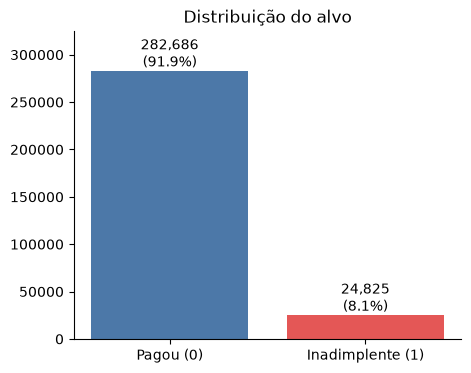

In [4]:
contagem = treino["target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(["Pagou (0)", "Inadimplente (1)"], contagem.values, color=["#4c78a8", "#e45756"])
for b, v in zip(barras, contagem.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(treino):.1%})", ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.15)
ax.set_title("Distribuição do alvo")
salvar("desbalanceamento")
plt.show()

### 1.2 Valores ausentes por coluna

67 de 122 colunas têm nulos; 41 com mais de 50%


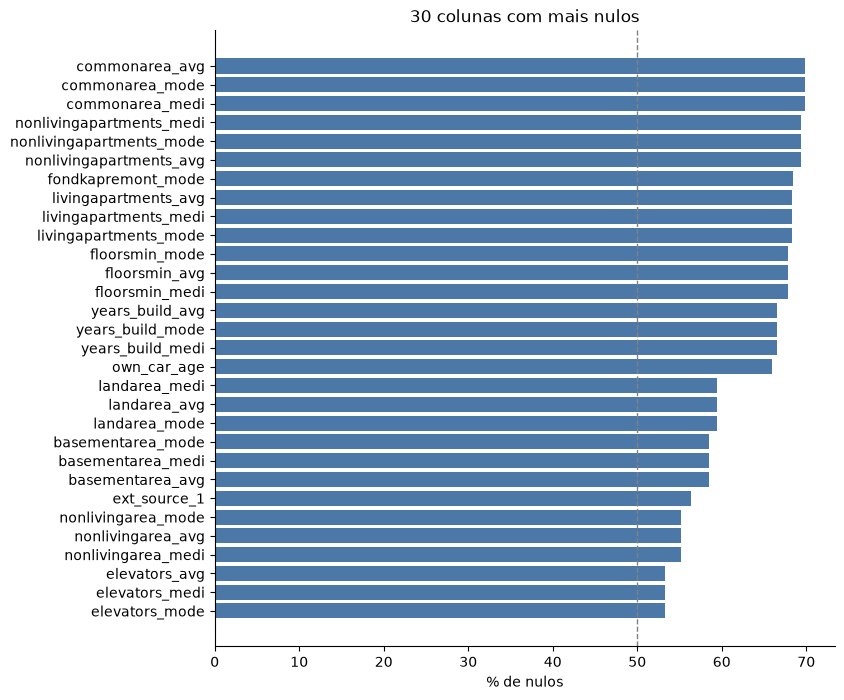

In [5]:
nulos = treino.isna().mean().sort_values(ascending=False)
nulos = nulos[nulos > 0]
print(f"{len(nulos)} de {treino.shape[1]} colunas têm nulos; {(nulos > 0.5).sum()} com mais de 50%")
top = nulos.head(30)[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top.index, top.values * 100, color="#4c78a8")
ax.axvline(50, color="gray", ls="--", lw=1)
ax.set_xlabel("% de nulos")
ax.set_title("30 colunas com mais nulos")
salvar("nulos")
plt.show()

### 1.3 A ausência diz algo sobre o risco?
Compara a taxa de inadimplência de quem tem o campo nulo com quem não tem. 

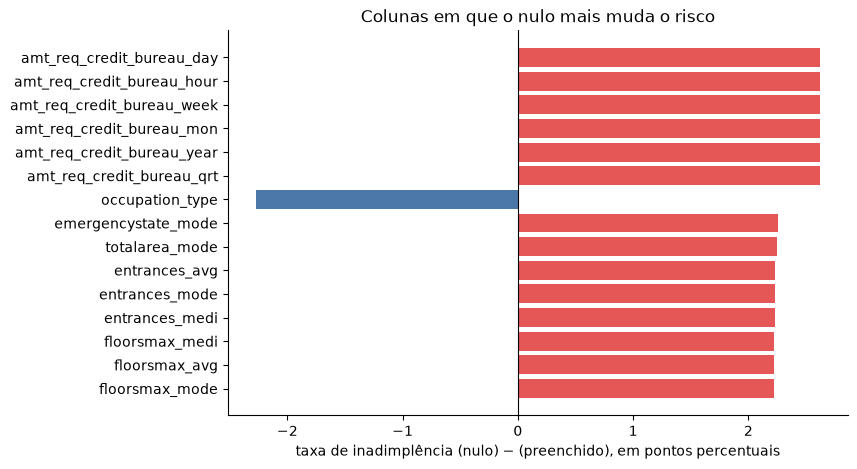

In [6]:
linhas = []
for col in nulos.index:
    m = treino[col].isna()
    if 0.01 < m.mean() < 0.99:
        linhas.append((col, treino.loc[m, "target"].mean() - treino.loc[~m, "target"].mean()))
dif = pd.Series(dict(linhas)).sort_values(key=abs, ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(dif.index, dif.values * 100, color=np.where(dif.values > 0, "#e45756", "#4c78a8"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("taxa de inadimplência (nulo) − (preenchido), em pontos percentuais")
ax.set_title("Colunas em que o nulo mais muda o risco")
salvar("nulos_risco")
plt.show()

### 1.4 `DAYS_EMPLOYED`

55,374 linhas (18.0%) com sentinela
name_income_type
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


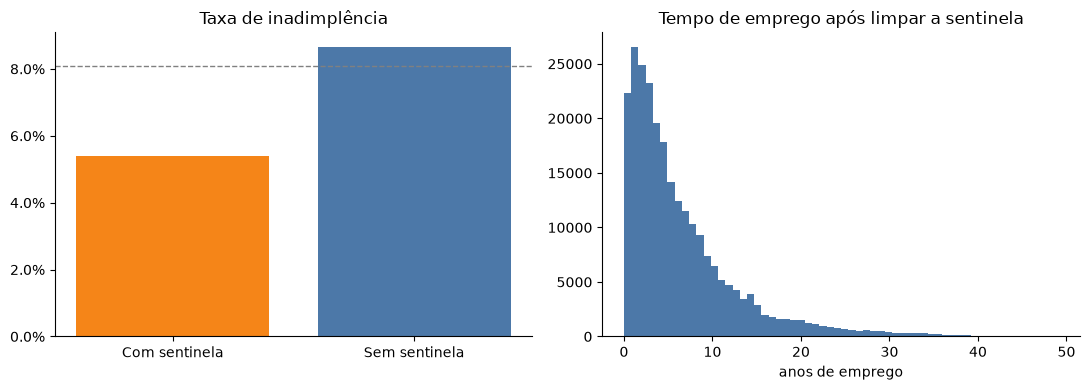

In [7]:
sent = treino["days_employed"] == 365243
print(f"{sent.sum():,} linhas ({sent.mean():.1%}) com sentinela")
print(treino.loc[sent, "name_income_type"].value_counts().head())

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(["Com sentinela", "Sem sentinela"], [treino.loc[sent, "target"].mean(), treino.loc[~sent, "target"].mean()], color=["#f58518", "#4c78a8"])
axs[0].axhline(taxa_geral, color="gray", ls="--", lw=1)
axs[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axs[0].set_title("Taxa de inadimplência")

treino["days_employed"] = treino["days_employed"].replace(365243, np.nan)
axs[1].hist(-treino["days_employed"].dropna() / 365, bins=60, color="#4c78a8")
axs[1].set_xlabel("anos de emprego"); axs[1].set_title("Tempo de emprego após limpar a sentinela")
plt.tight_layout(); salvar("sentinela")
plt.show()

### 1.5 Taxa de inadimplência por faixa (variáveis numéricas)

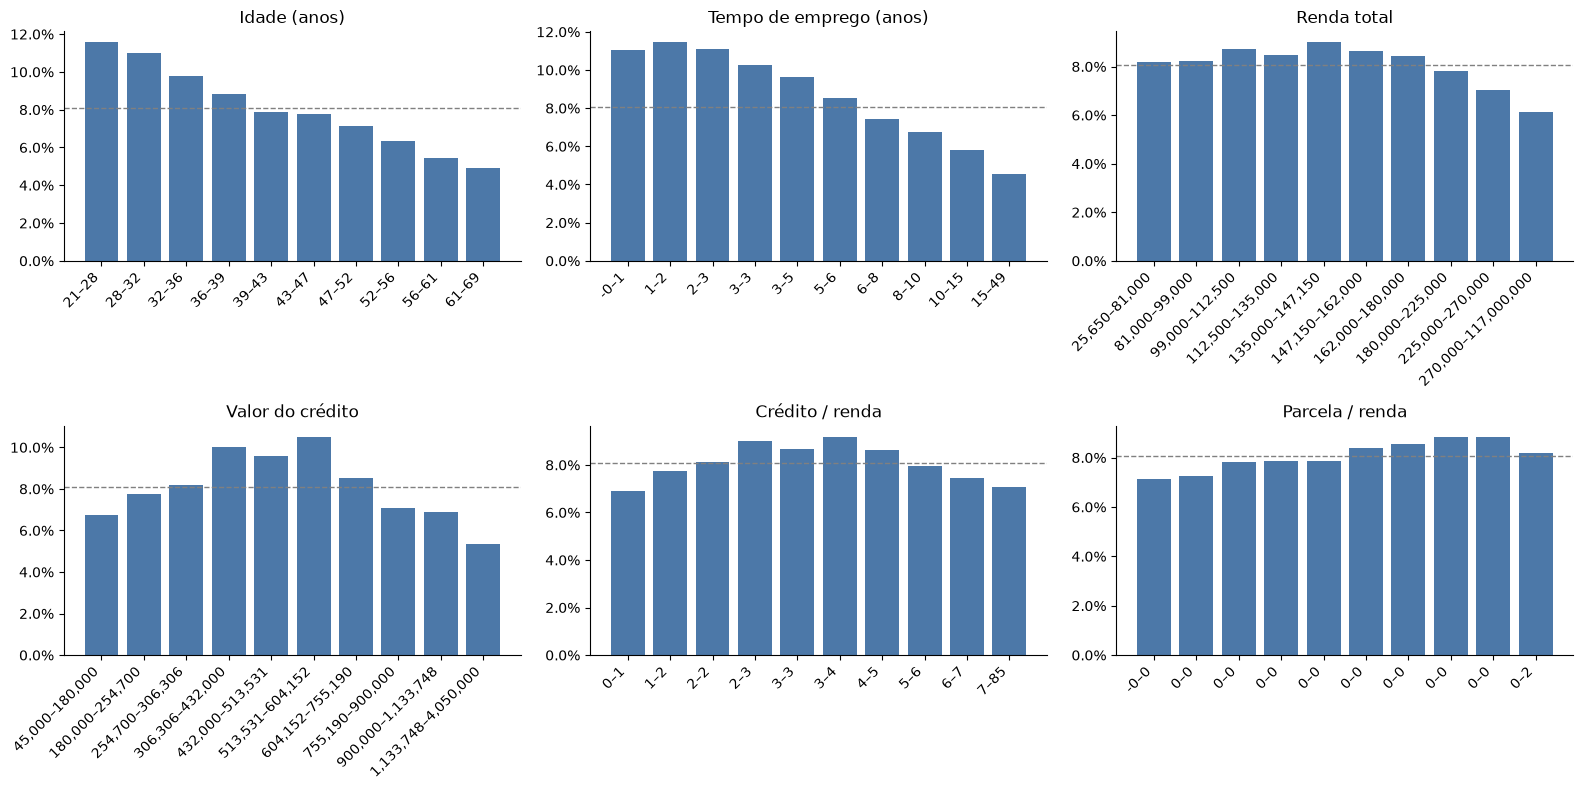

In [8]:
def taxa_por_faixa(ax, serie, titulo, q=10):
    faixa = pd.qcut(serie, q=q, duplicates="drop")
    taxa = treino.groupby(faixa, observed=True)["target"].mean()
    ax.bar(range(len(taxa)), taxa.values, color="#4c78a8")
    ax.set_xticks(range(len(taxa)), [f"{i.left:,.0f}–{i.right:,.0f}" for i in taxa.index], rotation=45, ha="right")
    ax.axhline(taxa_geral, color="gray", ls="--", lw=1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(titulo)

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
taxa_por_faixa(axs[0, 0], -treino["days_birth"] / 365, "Idade (anos)")
taxa_por_faixa(axs[0, 1], -treino["days_employed"] / 365, "Tempo de emprego (anos)")
taxa_por_faixa(axs[0, 2], treino["amt_income_total"], "Renda total")
taxa_por_faixa(axs[1, 0], treino["amt_credit"], "Valor do crédito")
taxa_por_faixa(axs[1, 1], treino["amt_credit"] / treino["amt_income_total"], "Crédito / renda")
taxa_por_faixa(axs[1, 2], treino["amt_annuity"] / treino["amt_income_total"], "Parcela / renda")
plt.tight_layout(); salvar("faixas")
plt.show()

### 1.6 `EXT_SOURCE_*` (scores externos)
Costumam ser as variáveis mais fortes da base. Compara a distribuição de quem pagou e de quem não pagou.

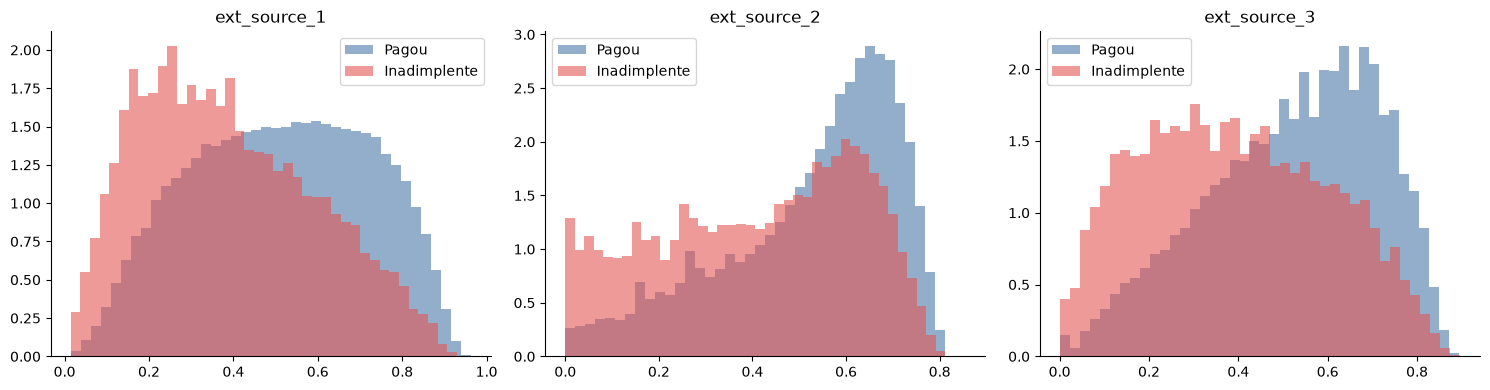

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, ["ext_source_1", "ext_source_2", "ext_source_3"]):
    for alvo, cor, nome in [(0, "#4c78a8", "Pagou"), (1, "#e45756", "Inadimplente")]:
        ax.hist(treino.loc[treino["target"] == alvo, col].dropna(), bins=40, density=True, alpha=0.6, color=cor, label=nome)
    ax.set_title(col); ax.legend()
plt.tight_layout(); salvar("ext_source")
plt.show()

### 1.7 Taxa de inadimplência por categoria

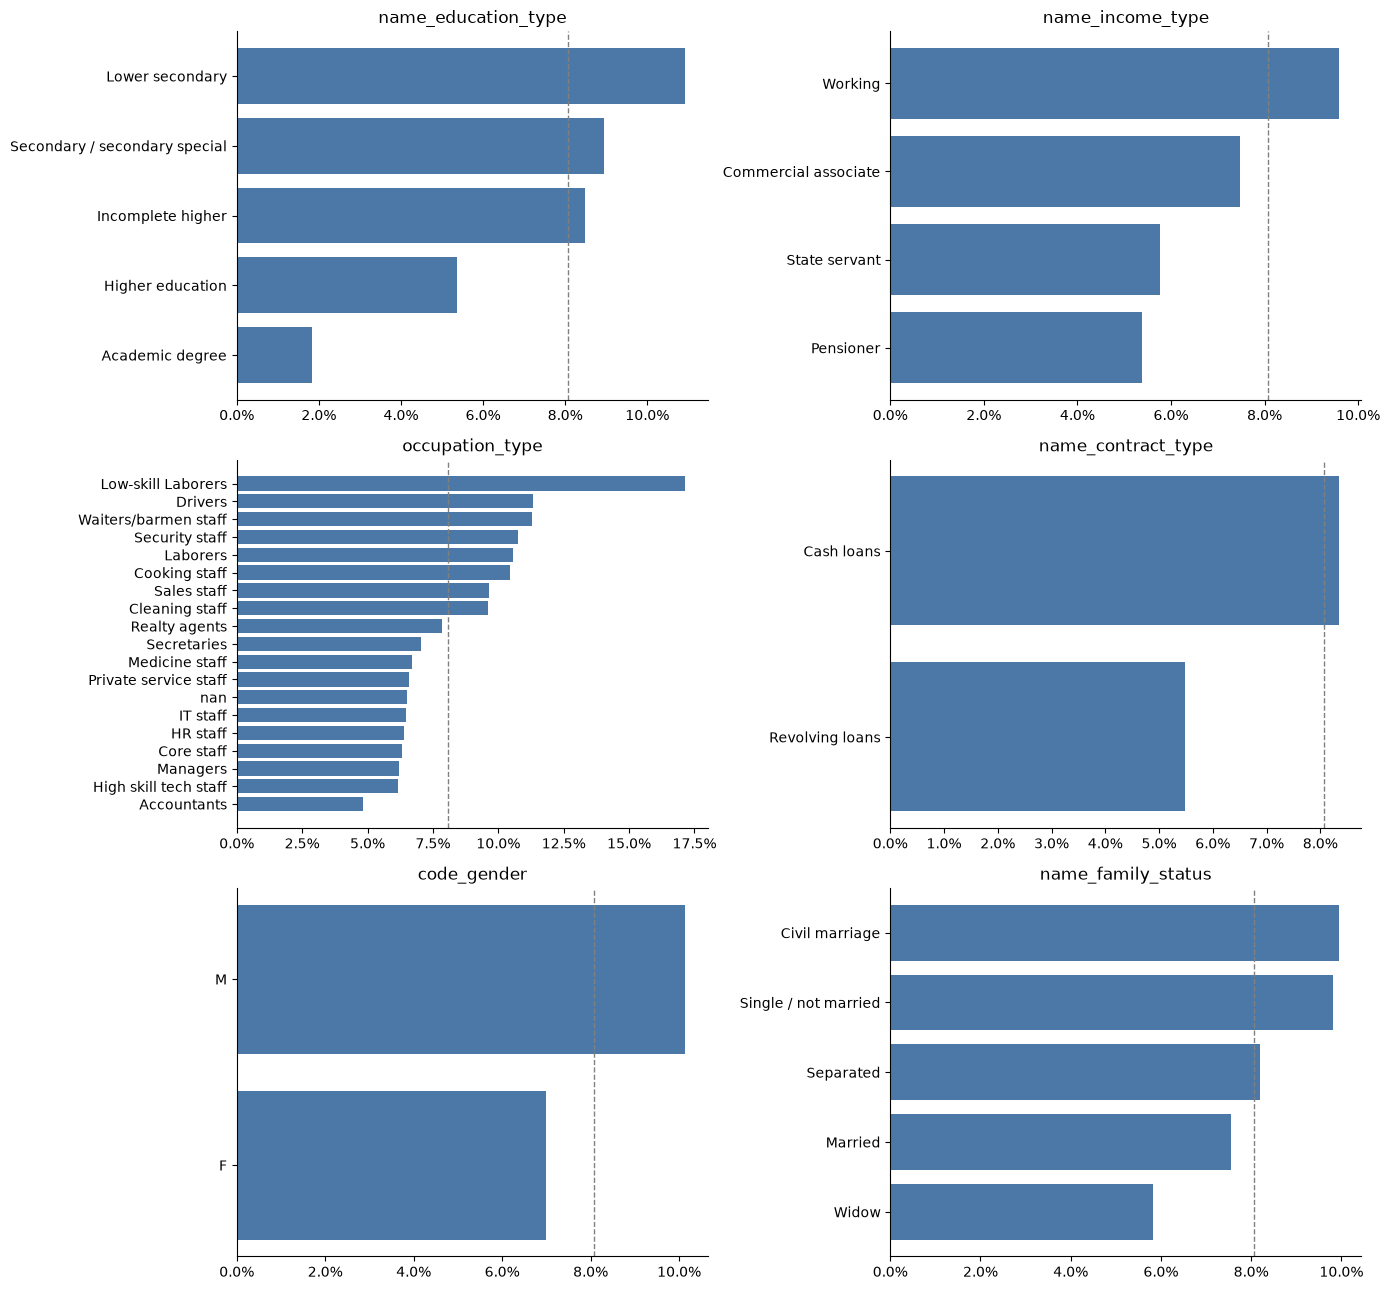

In [10]:
cats = ["name_education_type", "name_income_type", "occupation_type", "name_contract_type", "code_gender", "name_family_status"]
fig, axs = plt.subplots(3, 2, figsize=(14, 13))
for ax, col in zip(axs.ravel(), cats):
    g = treino.groupby(col, dropna=False)["target"].agg(["mean", "size"])
    g = g[g["size"] >= 100].sort_values("mean")
    ax.barh([str(i) for i in g.index], g["mean"], color="#4c78a8")
    ax.axvline(taxa_geral, color="gray", ls="--", lw=1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(col)
plt.tight_layout(); salvar("categorias")
plt.show()

### 1.8 Outliers e assimetria dos valores monetários
Escala log no eixo x para enxergar a cauda; boxplot mostra os pontos fora de 1,5·IQR.

/tmp/ipykernel_56530/3648521860.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1, i].boxplot(x, vert=False, showfliers=True, flierprops={"markersize": 2})
/tmp/ipykernel_56530/3648521860.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1, i].boxplot(x, vert=False, showfliers=True, flierprops={"markersize": 2})
/tmp/ipykernel_56530/3648521860.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1, i].boxplot(x, vert=False, showfliers=True, flierprops={"markersize": 2})
/tmp/ipykernel_56530/3648521860.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical

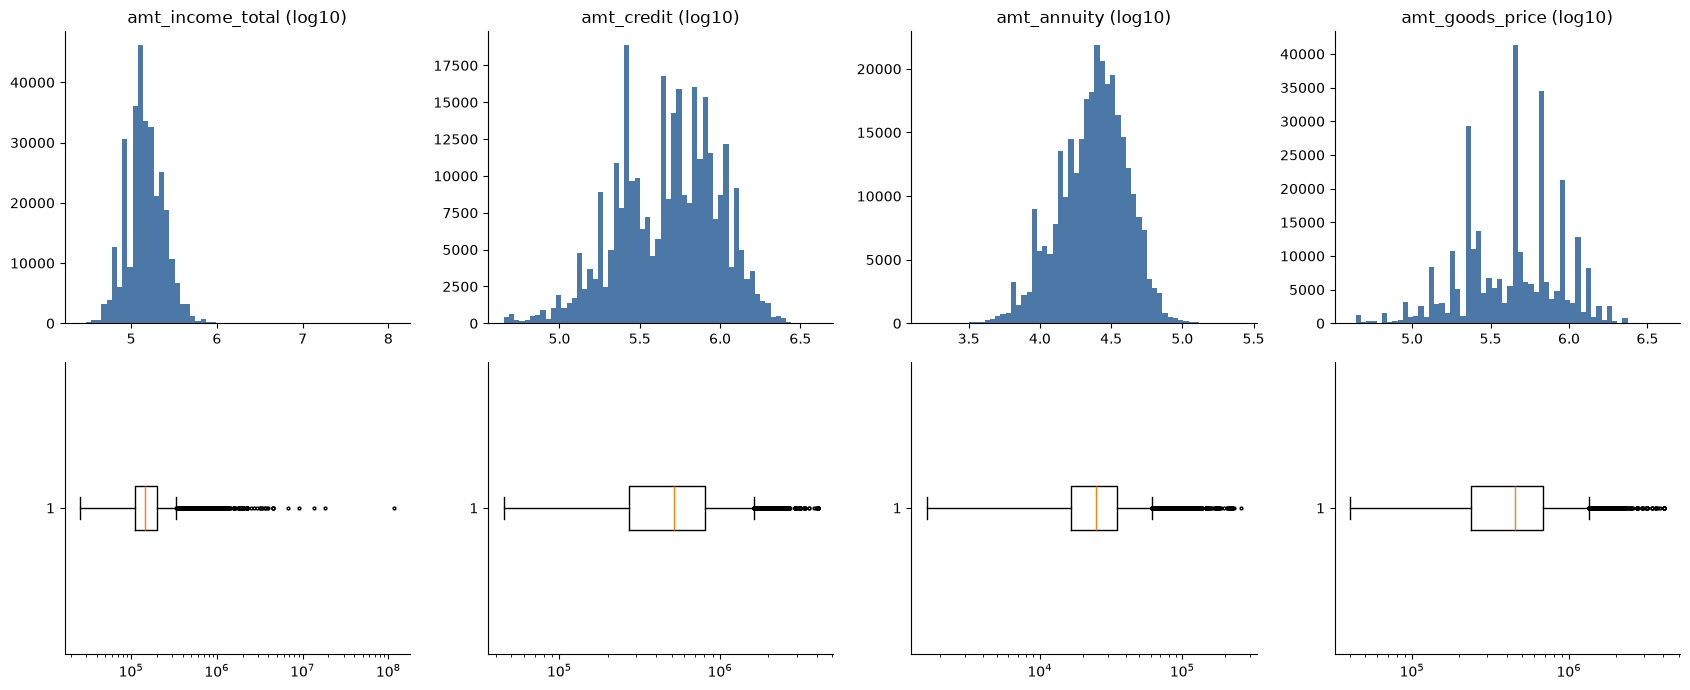

                       50%        99%      99.9%          max
amt_income_total  147150.0   472500.0   900000.0  117000000.0
amt_credit        513531.0  1854000.0  2517300.0    4050000.0
amt_annuity        24903.0    70006.5   110047.5     258025.5
amt_goods_price   450000.0  1800000.0  2250000.0    4050000.0


In [11]:
cols = ["amt_income_total", "amt_credit", "amt_annuity", "amt_goods_price"]
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
for i, col in enumerate(cols):
    x = treino[col].dropna()
    axs[0, i].hist(np.log10(x[x > 0]), bins=60, color="#4c78a8")
    axs[0, i].set_title(f"{col} (log10)")
    axs[1, i].boxplot(x, vert=False, showfliers=True, flierprops={"markersize": 2})
    axs[1, i].set_xscale("log")
plt.tight_layout(); salvar("outliers")
plt.show()
print(treino[cols].describe(percentiles=[.5, .99, .999]).T[["50%", "99%", "99.9%", "max"]])

### 1.9 Duplicatas e valores impossíveis

In [12]:
print("SK_ID_CURR duplicado:", treino["sk_id_curr"].duplicated().sum())
print("idade fora de 18–100:", (~(-treino["days_birth"] / 365).between(18, 100)).sum())
print("renda <= 0:", (treino["amt_income_total"] <= 0).sum())
print("code_gender = XNA:", (treino["code_gender"] == "XNA").sum())
print("cnt_fam_members < cnt_children:", (treino["cnt_fam_members"] < treino["cnt_children"]).sum())
print("cnt_children > 10:", (treino["cnt_children"] > 10).sum())

SK_ID_CURR duplicado: 0
idade fora de 18–100: 0
renda <= 0: 0
code_gender = XNA: 4
cnt_fam_members < cnt_children: 0
cnt_children > 10: 8


### 1.10 Correlação das variáveis numéricas com o alvo

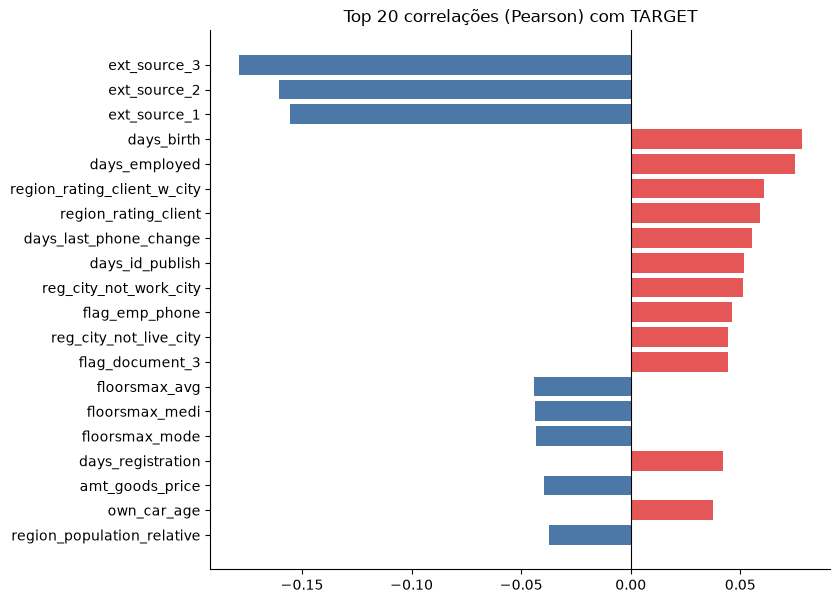

In [13]:
corr = treino.select_dtypes("number").corr()["target"].drop(["target", "sk_id_curr"]).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).head(20).index)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#e45756", "#4c78a8"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Top 20 correlações (Pearson) com TARGET")
salvar("correlacao")
plt.show()

## 2. Tabelas auxiliares

Até aqui só a tabela `application_train` foi explorada, e ela descreve o cliente no momento do pedido. As outras tabelas guardam o que aconteceu antes dele, como créditos em outras instituições, pedidos anteriores na Home Credit, parcelas pagas e extratos mensais. É nelas que devem sair as features mais fortes, mas antes de agregá-las convém saber quantos clientes têm algum histórico.

### 2.1 Cobertura: quem tem histórico e se isso muda o risco

Nem todo cliente da tabela `application_train` aparece nas tabelas auxiliares. Quem nunca teve cartão da Home Credit, por exemplo, não tem nenhuma linha em `credit_card_balance`. Para cada tabela que traz o `id` `sk_id_curr`, foi calculada a fração de clientes com ao menos uma linha e a taxa de inadimplência de quem tem e de quem não tem histórico.

Há dois objetivos. O primeiro é estimar quantos nulos as features agregadas terão, já que um cliente sem linhas não gera média, soma nem contagem. O segundo é verificar se a ausência de histórico muda o risco, porque nesse caso o nulo passa a ser informação e deve virar uma variável própria (um indicador "tem histórico"), em vez de ser imputado.

A `bureau_balance` ficou de fora porque não tem `sk_id_curr`. Ela se liga à `bureau` por `sk_id_bureau`, e entra na análise junto com essa tabela.

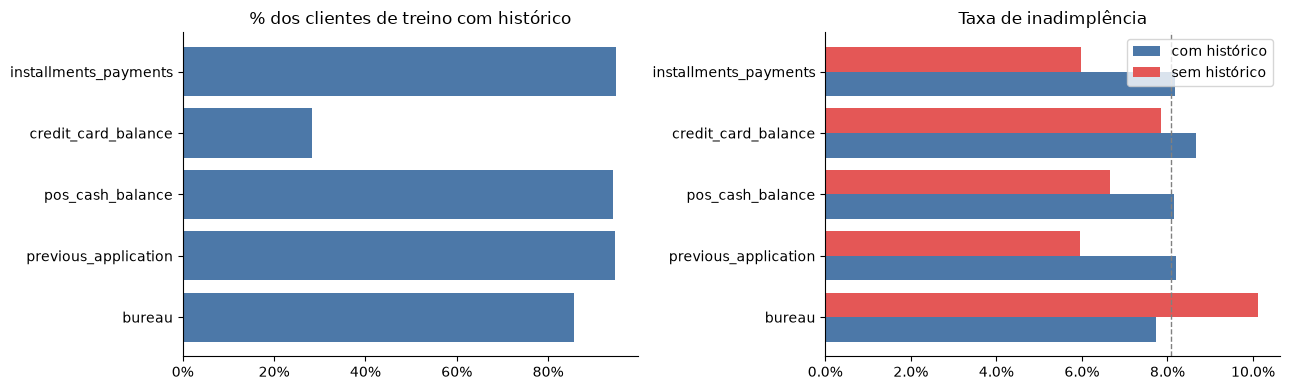

,cobertura,taxa_com,taxa_sem
tabela,,,
bureau,0.8569,0.0773,0.1012
previous_application,0.9465,0.0819,0.0596
pos_cash_balance,0.9412,0.0816,0.0666
credit_card_balance,0.2826,0.0867,0.0784
installments_payments,0.9484,0.0819,0.0598


In [14]:
tabelas = ["bureau", "previous_application", "pos_cash_balance", "credit_card_balance", "installments_payments"]
linhas = []
for tab in tabelas:
    q = f"""
        SELECT (a.sk_id_curr IS NOT NULL) AS tem, COUNT(*) AS n, AVG(t.target) AS taxa
        FROM application_train t
        LEFT JOIN (SELECT DISTINCT sk_id_curr FROM {tab}) a USING (sk_id_curr)
        GROUP BY 1
    """
    d = pd.read_sql(q, engine).set_index("tem")
    linhas.append({"tabela": tab, "cobertura": d.loc[True, "n"] / d["n"].sum(),
                   "taxa_com": d.loc[True, "taxa"], "taxa_sem": d.loc[False, "taxa"]})
cobertura = pd.DataFrame(linhas).set_index("tabela")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].barh(cobertura.index, cobertura["cobertura"], color="#4c78a8")
axs[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axs[0].set_title("% dos clientes de treino com histórico")
y = np.arange(len(cobertura))
axs[1].barh(y - 0.2, cobertura["taxa_com"], 0.4, label="com histórico", color="#4c78a8")
axs[1].barh(y + 0.2, cobertura["taxa_sem"], 0.4, label="sem histórico", color="#e45756")
axs[1].set_yticks(y, cobertura.index)
axs[1].axvline(taxa_geral, color="gray", ls="--", lw=1)
axs[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axs[1].set_title("Taxa de inadimplência"); axs[1].legend()
plt.tight_layout()
salvar("cobertura")
plt.show()
cobertura.round(4)